# Lab 4: Working with 'real' data

**Introduction**

In this lab we are going to work on how to estimate the background from 'real' data. Real is in air quotes because the data is actually from simplified simulations to make the problems manageable in a single lab. But the data will have some features that resemble that of real data sets.

In [7]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.optimize import curve_fit
import scipy.stats as stats
import h5py

In [8]:
hf = h5py.File('../../Shared/gammaray_lab4.h5', 'r')

hf.keys()

<KeysViewHDF5 ['data']>

In [9]:
data = np.array(hf.get('data'))

np.shape(data)
data[:,0]

hf.close()

# Problem

In this problem we are looking at the data from a gamma-ray satellite orbiting in low Earth orbit. It takes a reading of the number of particles detected every 100 milliseconds, and is in an approximately 90 minute orbit. While it is looking for gamma-ray bursts, virtually all of the particles detected are background cosmic rays.

As with most data, there are 'features.' Your lab instructor has helpfully incorporated the meta-data into your data file.

**1.** Examine the data. The columns are time (in gps seconds), Solar phase (deg) showing the position of the sun relative to the orbit, Earth longitude (deg) giving the position of the spacecraft relative to the ground, and particle counts. Make a few plots, generally exploring your data and making sure you understand it. Give a high level description of the data features you see. Specifically comment on whether you see signal contamination in your data, and how you plan to build a background pdf().

In [10]:
time = data[0,:] # Time in GPS seconds, row 0
solar_phase = data[1,:] # Solar phase in degrees, row 1
earth_long = data[2,:] # Earth longitude in degrees, row 2
counts = data[3,:] # Particle counts, row 3

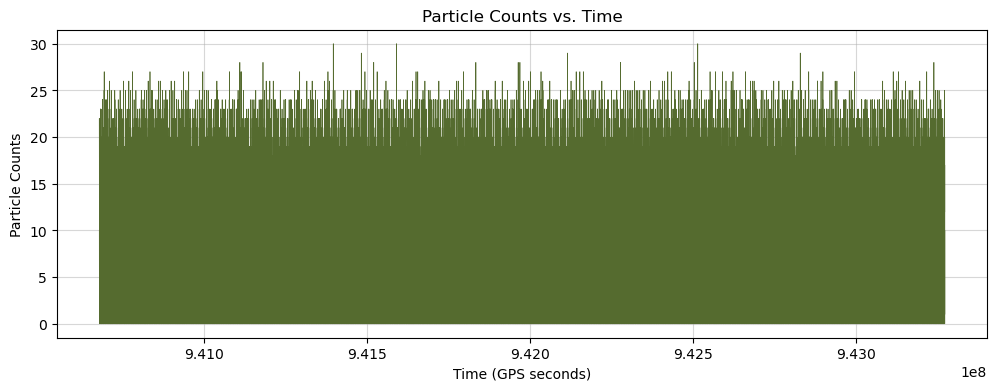

In [5]:
# Plotting particle counts vs. time to visualize how flux of particles changes with time

plt.figure(figsize=(12, 4))
plt.plot(time, counts, lw=0.5, color='darkolivegreen')
plt.xlabel('Time (GPS seconds)')
plt.ylabel('Particle Counts')
plt.title('Particle Counts vs. Time')
plt.grid(True, alpha=0.5)
plt.show()

**In our counts vs. time plot, we can see that there is a strong stable baseline with particle count fluctuations taking place. So the background radiation environment is steady during orbit, but we can see signal contamination in the form of the fluctation spikes which are most likely caused by transient events.**

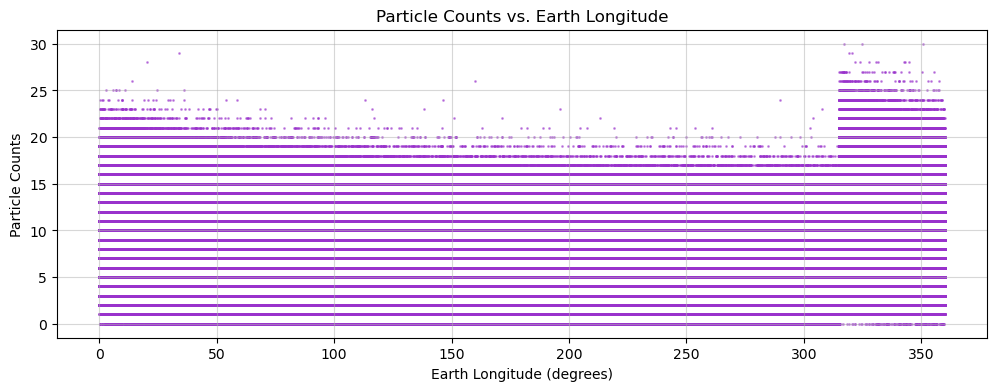

In [6]:
# Plotting particle counts vs. Earth longitude to visualize how flux of particles changes around Earth

plt.figure(figsize=(12, 4))
plt.scatter(earth_long, counts, s=1, alpha=0.5, color='darkorchid')
plt.xlabel('Earth Longitude (degrees)')
plt.ylabel('Particle Counts')
plt.title('Particle Counts vs. Earth Longitude')
plt.grid(True, alpha=0.5)
plt.show()

**The counts vs. longitude plot shows the counts at the longitudinal degrees as distinct horizonatal lines. There also looks like a big shift in the amount of counts towards the higher degrees beyond 300 degrees up to 360 degrees and then the particle count slowly returns back to the baseline afterwards. There is clear visible signal contamination in the anomaly region from about 310 degrees to 360 degrees because of the value of the counts suddenly shooting up. There are also scattering of individual dots from 0 to 360 degrees that are most likely transient events.**

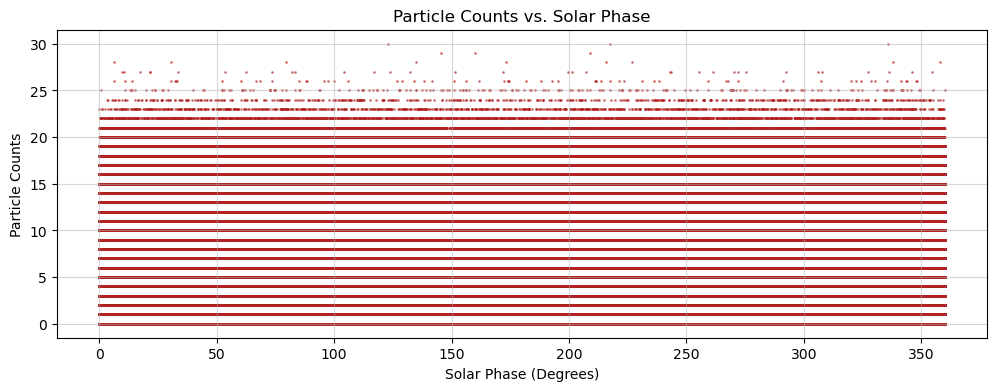

In [5]:
# Plotting particle counts vs. solar phase to visualize change in flux as spacecraft moves in orbit

plt.figure(figsize=(12, 4))
plt.scatter(solar_phase, counts, s=1, alpha=0.5, color='firebrick')
plt.xlabel('Solar Phase (Degrees)')
plt.ylabel('Particle Counts')
plt.title('Particle Counts vs. Solar Phase')
plt.grid(True, alpha=0.5)
plt.show()

**This counts vs. solar phase plot has the same horizonatal distinct lines for counts. However, this plot has a more uniform distribution unlike the previous counts vs. longitude plot. There is still some signal contamination in the form of the scattered dots representing high count values from transient events, but this isn't as extreme of signal contamination like we saw in the previous plot. So the signal contamination is most likely tied to Earth's coordinates rather than solar phase.**

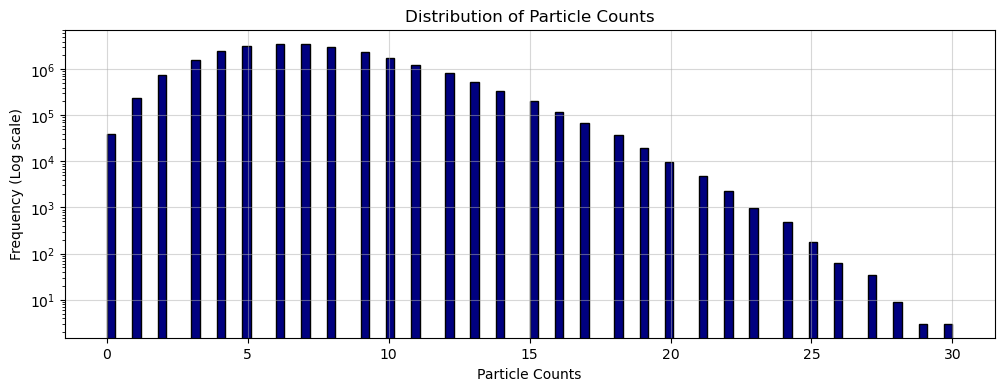

In [6]:
# Plotting histogram for the distribution of particle counts

plt.figure(figsize=(12, 4))
plt.hist(counts, bins=100, color='navy', edgecolor='black', log=True)
plt.xlabel('Particle Counts')
plt.ylabel('Frequency (Log scale)')
plt.title('Distribution of Particle Counts')
plt.grid(True, alpha=0.5)
plt.show()

**The histogram is in log-scale on the y-axis and we can see that it resembles a normal distribution with its peak centered at about 7 counts. There is visible signal contamination at the right end tail, where the tail seems to elevate again instead of dropping off smoothly to zero. So excess background flux or transient events are contaminating the data.**

**My plan to build the background pdf() consists of ditching a static global mean because our background is varying and not homogenous. So our background pdf() should be modeled as a function of the orbital positon so that we can calculate how the likelihood of finding an object changes with position in orbit. As well as combine the model with iterative sigma-clipping to handle and remove the transient spikes from the baseline that we see.**

**2.** The background is not consistent across the dataset. Find and describe as accurately as you can how the background changes.

In [11]:
# Binning, every 5 degrees from 0 to 360 degrees
bins = np.arange(0, 360, 5)
bin_indices = np.digitize(earth_long, bins)

# Calculating median and standard deviation of counts in every bin
bin_median = []
bin_std = []
bin_center = (bins[:-1] + bins[1:]) / 2

# Looping through each bin index to compute median and std and appends them to respective lists
for i in range(1, len(bins)):
    mask = (bin_indices == i)
    if np.sum(mask) > 0:
        bin_median.append(np.median(counts[mask]))
        bin_std.append(np.std(counts[mask]))
    else:
        bin_median.append(np.nan)
        bin_std.append(np.nan)

# Computed list of medians is converted into array
bin_median = np.array(bin_median)

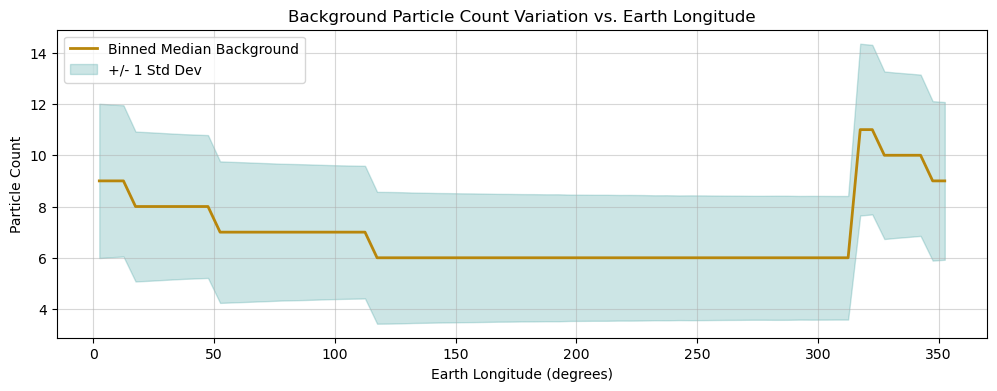

In [12]:
# PLotting the binned median counts vs. Earth longitude to see how background level shifts
plt.figure(figsize=(12, 4))
plt.plot(bin_center, bin_median, color='darkgoldenrod', lw=2, label='Binned Median Background')
plt.fill_between(bin_center, bin_median - np.array(bin_std), bin_median + np.array(bin_std), color='teal', alpha=0.2, label='+/- 1 Std Dev')
plt.xlabel('Earth Longitude (degrees)')
plt.ylabel('Particle Count')
plt.title('Background Particle Count Variation vs. Earth Longitude')
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

**The graph shows that the background count rate is changing across the different longitudes. We see that there is a constant 6 count rate from about 120 degrees to about 310 degrees where it suddenly shoots up to an 11 count rate. Then it slowly starts to decrease back to a 6 count rate from 310 degrees to 120 degrees. It decreases by about 1 count rate, with each successive lower integer lasting more longitudinal degrees than the previous until it reaches the 6 count rate. So there is a noticeable longitudinal window where the background jumps up before slowly returning back to normal.**

**3.** Create a model for the background that includes time dependence, and explicitly compare your model to the data. How good is your model of the background?

In [13]:
# Defining model function for variation in background
def background_model(x, baseline, amp, x0, sigma):
    return baseline + amp * np.exp(-((x - x0) ** 2) / (2 * sigma ** 2))

# Data filtered for any NaNs
val = ~np.isnan(bin_median)
x_data = bin_center[val]
y_data = bin_median[val]

# Fitting function and initial guesses
p0 = [6.5, 4.0, 340.0, 20.0] # Guesses for baseline, amplitude, peak, and width respectively
opt, cov = curve_fit(background_model, x_data, y_data, p0=p0)

In [14]:
# Evaluating model across the Earth longitude array
background_model = background_model(earth_long, *opt)

# Downsampling arrays since memory problems are occuring. So every 50th point is grabbed.
step = 50
time_sub = time[::step]
counts_sub = counts[::step]
background_sub = background_model[::step]
res_sub = counts_sub - background_sub

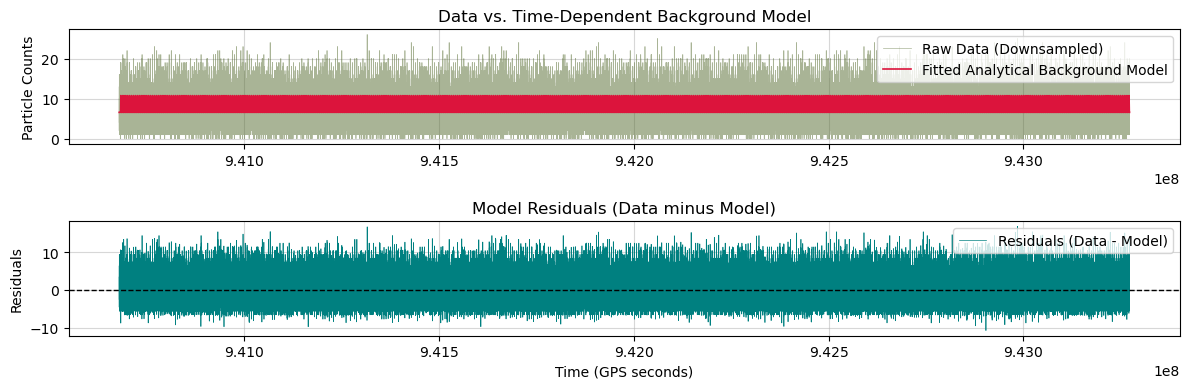

In [12]:
# Plotting data vs background model and residuals

plt.figure(figsize=(12, 4))

plt.subplot(2, 1, 1) # Light curve and fitted model (Top graph)
plt.plot(time_sub, counts_sub, lw=0.5, color='darkolivegreen', alpha=0.5, label='Raw Data (Downsampled)')
plt.plot(time_sub, background_sub, color='crimson', lw=1.2, label='Fitted Analytical Background Model')
plt.title('Data vs. Time-Dependent Background Model')
plt.ylabel('Particle Counts')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.5)

plt.subplot(2, 1, 2) # Residuals (Bottom graph)
plt.plot(time_sub, res_sub, lw=0.5, color='teal', label='Residuals (Data - Model)')
plt.axhline(0, color='black', linestyle='--', lw=1)
plt.title('Model Residuals (Data minus Model)')
plt.xlabel('Time (GPS seconds)')
plt.ylabel('Residuals')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

**It looks like my model of the background is doing pretty well with tracking the orbital trends. When checking out the model residuals, we can see that the distribution is symmetrically centered about zero for the background. Meanwhile the true contamination spikes and transient events can be seen as deviations above the model. So it does well on helping reduce systematic background drift without completely supressing true physical signals.**

**4.** Because the background varies, your discovery sensitivity threshold (how many particles you would need to see) also varies. What is the '5-sigma' threshold for a 100 millisecond GRB at different times?

In [14]:
# Defining timestep of dataset
delta_t = np.median(np.diff(time))

# Converting background model rate to 100 ms
duration = 0.1 # Seconds (100 ms)
scale_factor = duration / delta_t

# Background counts in 100 ms 
mu_100 = background_model * scale_factor

# Calculating 5-sigma p-value using standard normal distribution
p_5sigma = stats.norm.sf(5)

# P(X >= N) <= p_5sigma, getting Poisson count threshold for each time step
threshold_5sigma = stats.poisson.ppf(1 - p_5sigma, mu_100)

# Downsampling since memory problems are occuring
step = 50
time_sub = time[::step]
mu_sub = mu_100[::step]
threshold_sub = threshold_5sigma[::step]

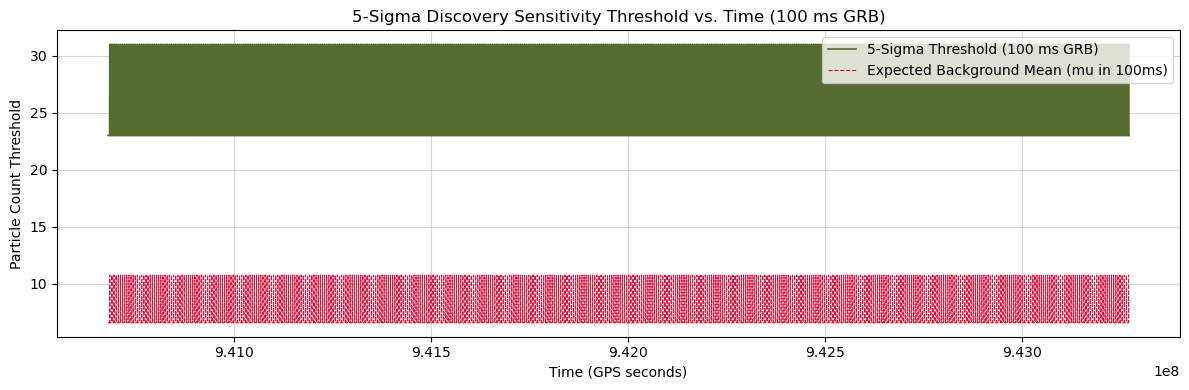

Minimum 5-sigma threshold (Orbit): 23.0 counts
Maximum 5-sigma threshold (Anomaly zone): 31.0 counts


In [15]:
# Plotting the 5-Sigma Threshold Over Time

plt.figure(figsize=(12, 4))
plt.plot(time_sub, threshold_sub, color='darkolivegreen', lw=1.2, label='5-Sigma Threshold (100 ms GRB)')
plt.plot(time_sub, mu_sub, color='crimson', lw=0.8, linestyle='--', label='Expected Background Mean (mu in 100ms)')
plt.title('5-Sigma Discovery Sensitivity Threshold vs. Time (100 ms GRB)')
plt.xlabel('Time (GPS seconds)')
plt.ylabel('Particle Count Threshold')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

# Threshold variance
print(f"Minimum 5-sigma threshold (Orbit): {np.min(threshold_5sigma):.1f} counts")
print(f"Maximum 5-sigma threshold (Anomaly zone): {np.max(threshold_5sigma):.1f} counts")

**5.** While this is simulated data, it is based on a real effect seen by low Earth orbit satellites. Can you identify the cause of the variable background and propose a physical model?

**The cause of the variable background is the Van Allen Radiation belt that is dipping closer to the Earth's surface in the South Atlantic area due to a weaker and uneven magnetic field. For the physical model, I think we could use geomagnetic coordinates and magnetic field intensity over geographic coordinates such as longitude. Since background particle flux scales inversely with the magnetic field strength, regions where the field lines dip and allow radiation to come into contact with the spacecraft's orbit are seen as sharp peaks.**